<a href="https://colab.research.google.com/github/mrpunith-1920/gnn-fraud-detection/blob/main/08_gnnexplainer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
!pip install torch_geometric networkx

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv, GCNConv, GATConv
from torch_geometric.utils import k_hop_subgraph
from torch_geometric.explain import Explainer, GNNExplainer
from sklearn.metrics import f1_score

path = '/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/'
data = torch.load(path + 'elliptic_graph.pt', weights_only=False)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
data = data.to(device)
names = [f'local_{i}' for i in range(1, 94)] + [f'agg_{i}' for i in range(1, 73)]

class GNN(torch.nn.Module):
    def __init__(self, in_dim, hidden=64, kind='sage', layers=2):
        super().__init__()
        Conv = {'gcn': GCNConv, 'sage': SAGEConv, 'gat': GATConv}[kind]
        dims = [in_dim] + [hidden] * layers
        self.convs = torch.nn.ModuleList([Conv(dims[i], dims[i+1]) for i in range(layers)])
        self.out = torch.nn.Linear(hidden, 2)

    def embed(self, x, edge_index):
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, 0.3, training=self.training)
        return x

    def forward(self, x, edge_index):
        return self.out(self.embed(x, edge_index))

model = GNN(data.num_features, 64, 'sage', 2).to(device)
model.load_state_dict(torch.load(path + 'graphsage.pth', map_location=device))
model.eval()
print(device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cpu


In [ ]:
with torch.no_grad():
    prob_all = F.softmax(model(data.x, data.edge_index), 1)[:, 1]
pred_all = (prob_all > 0.5).long()
te = data.test_mask
print('Test F1:', round(f1_score(data.y[te].cpu(), pred_all[te].cpu()), 3))

hits_all = ((pred_all == 1) & (data.y == 1) & te).nonzero().flatten().cpu().numpy()
print('Correctly flagged fraud in test period:', len(hits_all))

cand = hits_all[:400]
sizes = []
for nd in cand:
    _, ei, _, _ = k_hop_subgraph(int(nd), 2, data.edge_index, num_nodes=data.num_nodes)
    sizes.append(ei.size(1))
sizes = np.array(sizes)
print('Edges in 2-hop neighbourhood: median', int(np.median(sizes)), '| max', int(sizes.max()))

thr = 6
while (sizes >= thr).sum() < 5 and thr > 2:
    thr -= 1
big = cand[sizes >= thr]
print('Cut-off (edges):', thr, '| candidates:', len(big), 'of', len(cand))

rng = np.random.default_rng(0)
cases = rng.choice(big, size=min(5, len(big)), replace=False).tolist()
print(cases)
print([round(float(prob_all[c]), 3) for c in cases])

Test F1: 0.655
Correctly flagged fraud in test period: 666
Edges in 2-hop neighbourhood: median 1 | max 233
Cut-off (edges): 5 | candidates: 5 of 400
[157681, 142234, 148166, 136312, 136935]
[1.0, 0.99, 0.999, 1.0, 1.0]


In [ ]:
explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=200),
    explanation_type='model',
    node_mask_type='attributes',
    edge_mask_type='object',
    model_config=dict(mode='multiclass_classification', task_level='node', return_type='raw'),
)

HOPS = 2

def explain(node):
    subset, sub_ei, mapping, _ = k_hop_subgraph(node, HOPS, data.edge_index,
                                                relabel_nodes=True, num_nodes=data.num_nodes)
    c = int(mapping[0])
    exp = explainer(data.x[subset], sub_ei, index=c)
    return exp, subset, sub_ei, c

In [ ]:
node = cases[0]
exp, subset, sub_ei, c = explain(node)

with torch.no_grad():
    p_sub = F.softmax(model(data.x[subset], sub_ei), 1)[c, 1].item()
print('Probability, full graph:', round(prob_all[node].item(), 4), '| subgraph:', round(p_sub, 4))
print('Subgraph nodes:', len(subset), '| edges:', sub_ei.size(1))

em = exp.edge_mask.cpu()
print('Edges with non-zero importance:', int((em > 0).sum()))
for i in em.argsort(descending=True)[:5]:
    print(int(subset[sub_ei[0, i]]), '->', int(subset[sub_ei[1, i]]), 'importance', round(float(em[i]), 3))

nm = exp.node_mask[c].cpu()
print([(names[i], round(float(nm[i]), 3)) for i in nm.argsort(descending=True)[:5]])

Probability, full graph: 1.0 | subgraph: 1.0
Subgraph nodes: 60 | edges: 63
Edges with non-zero importance: 63
158690 -> 157681 importance 0.943
157615 -> 157616 importance 0.943
160978 -> 157681 importance 0.943
158844 -> 157681 importance 0.09
161006 -> 157681 importance 0.09
[('agg_55', 0.619), ('local_2', 0.617), ('local_55', 0.613), ('agg_37', 0.61), ('local_53', 0.604)]


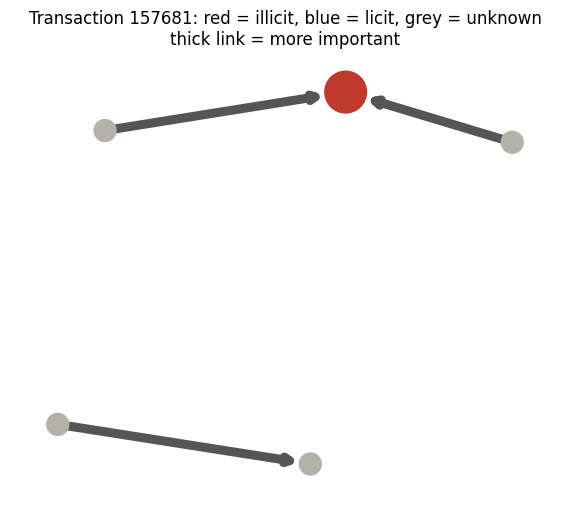

In [ ]:
def plot_case(node, exp, subset, sub_ei, c, fname=None):
    em = exp.edge_mask.cpu().numpy()
    if em.size == 0 or em.max() <= 0:
        print('No edges to plot for', node)
        return
    y_sub = data.y[subset].cpu().numpy()
    keep = np.where(em > 0.1 * em.max())[0]
    G = nx.DiGraph()
    G.add_node(c)
    for k in keep:
        G.add_edge(int(sub_ei[0, k]), int(sub_ei[1, k]), w=float(em[k]))
    col = ['#c0392b' if y_sub[i] == 1 else '#2f6fb3' if y_sub[i] == 0 else '#b4b2a9' for i in G.nodes]
    size = [900 if i == c else 250 for i in G.nodes]
    widths = [0.5 + 6 * G[u][v]['w'] / em.max() for u, v in G.edges]
    plt.figure(figsize=(5.5, 4.5))
    nx.draw(G, nx.spring_layout(G, seed=1), node_color=col, node_size=size, width=widths,
            arrowsize=10, edge_color='#555', with_labels=False)
    plt.title(f'Transaction {node}: red = illicit, blue = licit, grey = unknown\nthick link = more important')
    if fname:
        plt.savefig(path + fname, dpi=200, bbox_inches='tight')
    plt.show()

plot_case(node, exp, subset, sub_ei, c, 'gnnexp_case1.png')

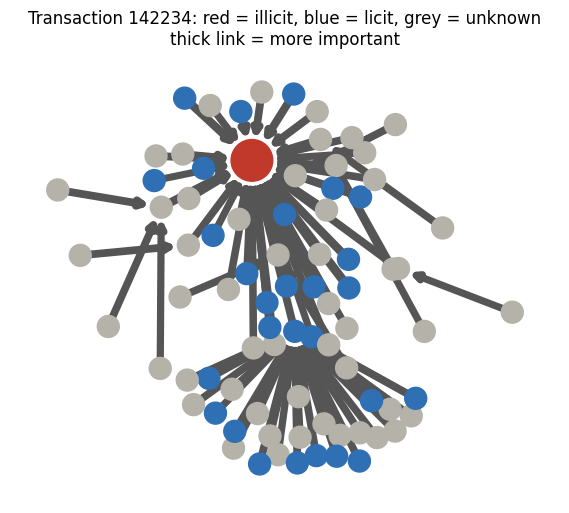

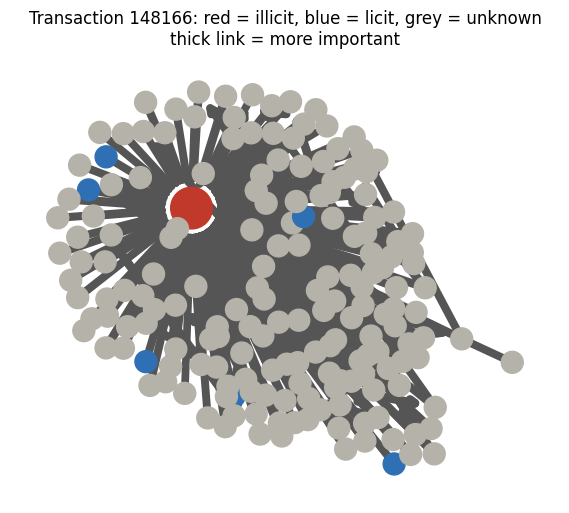

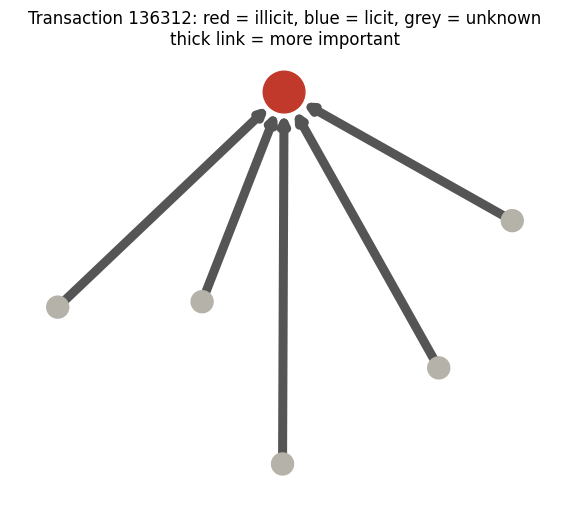

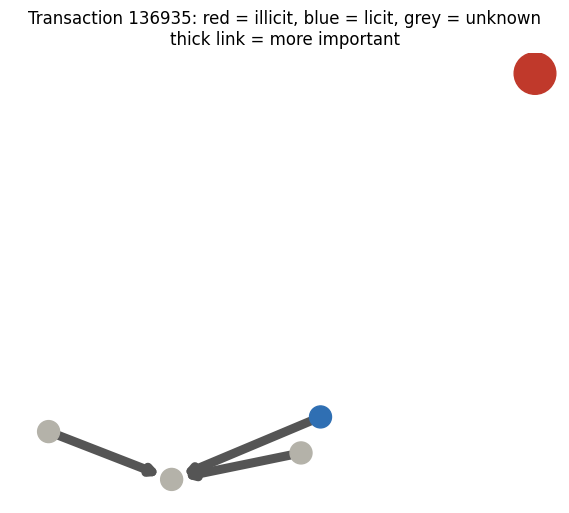

,Case,Node,Prob,Edges used,Prob after removing top-2,Prob after removing 2 random,Stability (Jaccard)
0,1,157681,1.000,63,1.000,1.000,0.07
1,2,142234,0.990,80,0.990,0.990,0.25
2,3,148166,0.999,233,0.999,0.999,0.00
3,4,136312,1.000,52,1.000,1.000,0.08
4,5,136935,1.000,5,1.000,0.999,1.00


In [ ]:
def prob_center(subset, ei, c):
    with torch.no_grad():
        return F.softmax(model(data.x[subset], ei), 1)[c, 1].item()

rows = []
for n, node in enumerate(cases, 1):
    exp, subset, sub_ei, c = explain(node)
    if sub_ei.size(1) == 0:
        print('Case', n, 'has no links, skipped')
        continue
    if n > 1:
        plot_case(node, exp, subset, sub_ei, c, f'gnnexp_case{n}.png')
    em = exp.edge_mask.cpu()
    pool = (em > 0).nonzero().flatten()
    if len(pool) < 3:
        print('Case', n, 'has fewer than 3 important links, skipped')
        continue
    k = min(2, len(pool) // 2)
    base = prob_center(subset, sub_ei, c)

    def drop(idx):
        keep = torch.ones(sub_ei.size(1), dtype=torch.bool)
        keep[idx] = False
        return prob_center(subset, sub_ei[:, keep.to(sub_ei.device)], c)

    p_top = drop(em.argsort(descending=True)[:k])
    g = torch.Generator().manual_seed(0)
    p_rand = np.mean([drop(pool[torch.randperm(len(pool), generator=g)[:k]]) for _ in range(10)])

    runs = [em] + [explain(node)[0].edge_mask.cpu() for _ in range(2)]
    tops = [set(r.argsort(descending=True)[:5].tolist()) for r in runs]
    jac = np.mean([len(a & b) / len(a | b) for i, a in enumerate(tops) for b in tops[i+1:]])

    rows.append({'Case': n, 'Node': node, 'Prob': round(base, 3), 'Edges used': len(pool),
                 f'Prob after removing top-{k}': round(p_top, 3),
                 f'Prob after removing {k} random': round(float(p_rand), 3),
                 'Stability (Jaccard)': round(float(jac), 2)})

res = pd.DataFrame(rows)
res.to_csv(path + 'gnnexplainer_results.csv', index=False)
res

In [ ]:
from scipy.stats import spearmanr

def margin(subset, ei, c):
    with torch.no_grad():
        o = model(data.x[subset], ei)[c]
    return (o[1] - o[0]).item()

def get_mask(sub_x, sub_ei, c, seed):
    torch.manual_seed(seed)
    ex = Explainer(model=model, algorithm=GNNExplainer(epochs=300, edge_size=0.05),
                   explanation_type='model', node_mask_type='attributes', edge_mask_type='object',
                   model_config=dict(mode='multiclass_classification', task_level='node', return_type='raw'))
    return ex(sub_x, sub_ei, index=c).edge_mask.cpu()

rows = []
for n, node in enumerate(cases, 1):
    subset, sub_ei, mapping, _ = k_hop_subgraph(node, 2, data.edge_index, relabel_nodes=True, num_nodes=data.num_nodes)
    c = int(mapping[0]); sub_x = data.x[subset]
    E = sub_ei.size(1)
    if E < 10:
        print('Case', n, 'has only', E, 'links, skipped'); continue

    masks = [get_mask(sub_x, sub_ei, c, s) for s in range(3)]
    stab = np.mean([spearmanr(masks[i].numpy(), masks[j].numpy())[0] for i in range(3) for j in range(i+1, 3)])
    avg = torch.stack(masks).mean(0)

    k = max(2, int(0.1 * E))
    base = margin(subset, sub_ei, c)

    def after_removal(idx):
        keep = torch.ones(E, dtype=torch.bool); keep[idx] = False
        return margin(subset, sub_ei[:, keep.to(sub_ei.device)], c)

    drop_top = base - after_removal(avg.argsort(descending=True)[:k])
    g = torch.Generator().manual_seed(0)
    drop_rand = np.mean([base - after_removal(torch.randperm(E, generator=g)[:k]) for _ in range(20)])

    rows.append({'Case': n, 'Node': node, 'Links': E, 'Removed k': k, 'Base margin': round(base, 2),
                 'Drop, top-k': round(drop_top, 3), 'Drop, random-k': round(float(drop_rand), 3),
                 'Stability (Spearman)': round(float(stab), 2)})

res2 = pd.DataFrame(rows)
res2.to_csv(path + 'gnnexplainer_results_v2.csv', index=False)
res2

Case 5 has only 5 links, skipped


,Case,Node,Links,Removed k,Base margin,"Drop, top-k","Drop, random-k",Stability (Spearman)
0,1,157681,63,6,10.20,-0.013,0.079,-0.14
1,2,142234,81,8,4.60,-0.021,-0.005,0.00
2,3,148166,233,23,6.93,0.100,-0.015,0.02
3,4,136312,53,5,9.89,0.063,-0.004,0.12


In [ ]:
def neighbour_summary(node):
    ei = data.edge_index
    nbrs = torch.unique(torch.cat([ei[1][ei[0] == node], ei[0][ei[1] == node]]))
    lab = data.y[nbrs].cpu().numpy()
    return {'neighbours': len(nbrs), 'illicit': int((lab == 1).sum()), 'licit': int((lab == 0).sum()), 'unknown': int((lab == -1).sum())}

for nd in cases:
    print(nd, neighbour_summary(nd))

157681 {'neighbours': 53, 'illicit': 0, 'licit': 8, 'unknown': 45}
142234 {'neighbours': 43, 'illicit': 0, 'licit': 18, 'unknown': 25}
148166 {'neighbours': 177, 'illicit': 0, 'licit': 6, 'unknown': 171}
136312 {'neighbours': 48, 'illicit': 0, 'licit': 10, 'unknown': 38}
136935 {'neighbours': 1, 'illicit': 0, 'licit': 0, 'unknown': 1}


In [ ]:
for node in cases[:4]:
    subset, sub_ei, mapping, _ = k_hop_subgraph(node, 2, data.edge_index, relabel_nodes=True, num_nodes=data.num_nodes)
    c = int(mapping[0])
    empty = torch.empty((2, 0), dtype=torch.long, device=sub_ei.device)
    print(node, 'margin with links:', round(margin(subset, sub_ei, c), 2),
          '| alone:', round(margin(subset, empty, c), 2))

157681 margin with links: 10.2 | alone: 10.52
142234 margin with links: 4.6 | alone: 4.42
148166 margin with links: 6.93 | alone: 9.26
136312 margin with links: 9.89 | alone: 9.04


In [ ]:
data.edge_index = ei_full
print(data.edge_index.shape)

torch.Size([2, 234355])


In [ ]:
data = torch.load(path + 'elliptic_graph.pt', weights_only=False).to(device)
print(data.edge_index.shape)

torch.Size([2, 234355])


In [ ]:
from sklearn.metrics import precision_score, recall_score, average_precision_score, roc_auc_score

def train_gnn(kind, epochs=200, hidden=64, lr=0.005, seed=42, layers=2):
    torch.manual_seed(seed)
    m = GNN(data.num_features, hidden, kind, layers).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=5e-4)
    n_fraud = (data.y[data.train_mask] == 1).sum().item()
    n_legit = (data.y[data.train_mask] == 0).sum().item()
    weights = torch.tensor([1.0, n_legit / n_fraud]).to(device)
    for epoch in range(epochs):
        m.train()
        opt.zero_grad()
        out = m(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask], weight=weights)
        loss.backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        out = m(data.x, data.edge_index)
        prob = F.softmax(out, dim=1)[:, 1][data.test_mask].cpu().numpy()
    y_true = data.y[data.test_mask].cpu().numpy()
    pred = (prob > 0.5).astype(int)
    row = {'Model': kind.upper(), 'Layers': layers, 'Seed': seed,
           'Precision': precision_score(y_true, pred), 'Recall': recall_score(y_true, pred),
           'F1': f1_score(y_true, pred), 'PR-AUC': average_precision_score(y_true, prob),
           'ROC-AUC': roc_auc_score(y_true, prob)}
    return m, row

In [ ]:
print(device, data.edge_index.shape)

cpu torch.Size([2, 234355])
